# 03 – Mehrteilchen-Clustersimulation und Übergabe an Team 2

**Team 1 – Physikalisches Basismodell** (§9, Schritte 8 und 10; §17)

2D-Brownian-Dynamik von N Protozellen (R = 500 nm) in einer periodischen Box,
Kraftbegrenzung 20 pN, dt = 1×10⁻⁷ s (Stabilitätsregel, §18 Fehler 6).

**Warum zwei Szenarien?** Mit dem Diffusionskoeffizienten des Aufgabenblatts
(D = 1×10⁻¹⁶ m²/s) diffundiert eine Zelle in machbarer Simulationszeit nur
wenige Nanometer – verdünnte Zufallsstarts kommen nie in den Kraftbereich.
Deshalb:

1. **Verdünnte Basislinie** (Box 20 µm, Zufallsstart): das ehrliche Ergebnis
   „keine Clusterbildung durch Einzelpaar-Kräfte“ (genau §10 für 30–100 nm).
2. **Vorgeclusterte Starts** (Gitter, Abstands-Sweep): Persistenz vs. Verdampfen
   bestehender Kontakte – das ist es, was die §11-Metriken messen.

In [1]:
import sys
from pathlib import Path
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from src.constants import DEBYE_LENGTHS
from src.potentials import ProtocellForces
from src.brownian_cluster import BrownianClusterSim, lattice_positions
from src.metrics import cluster_metrics, contact_graph, CONTACT_ZONES
from src.export import export_run, make_run_id
from src.plots import setup_style, save_fig

setup_style()

DT = 1e-7
FORCE_CAP = 20e-12
BOX = 20e-6
R_NM = 500.0
SEED = 42
MATERIALS = {"PMBC": 5e-21, "Fettsäure": 0.5e-21}


def run_cluster(model, mode, x0, n, steps, record_every=50, *, seed):
    """Läuft eine Cluster- Simulation; liefert (t, x, pair_rows)-Frames."""
    sim = BrownianClusterSim(n=n, R=R_NM * 1e-9, box=BOX, dt=DT,
                             seed=seed, force_cap=FORCE_CAP, x=x0)
    frames = []
    for step in range(1, steps + 1):
        sim.step(model, mode=mode)
        if step % record_every == 0:
            frames.append((step * DT, sim.x.copy(), sim.pair_distance_table()))
    return frames


## Szenario 1: verdünnte Basislinie

N = 20 Zellen, gleichmäßig zufällig in der 20-µm-Box – mittlerer
Partikelabstand ~4.5 µm, Kraftreichweite ≤ 100 nm.

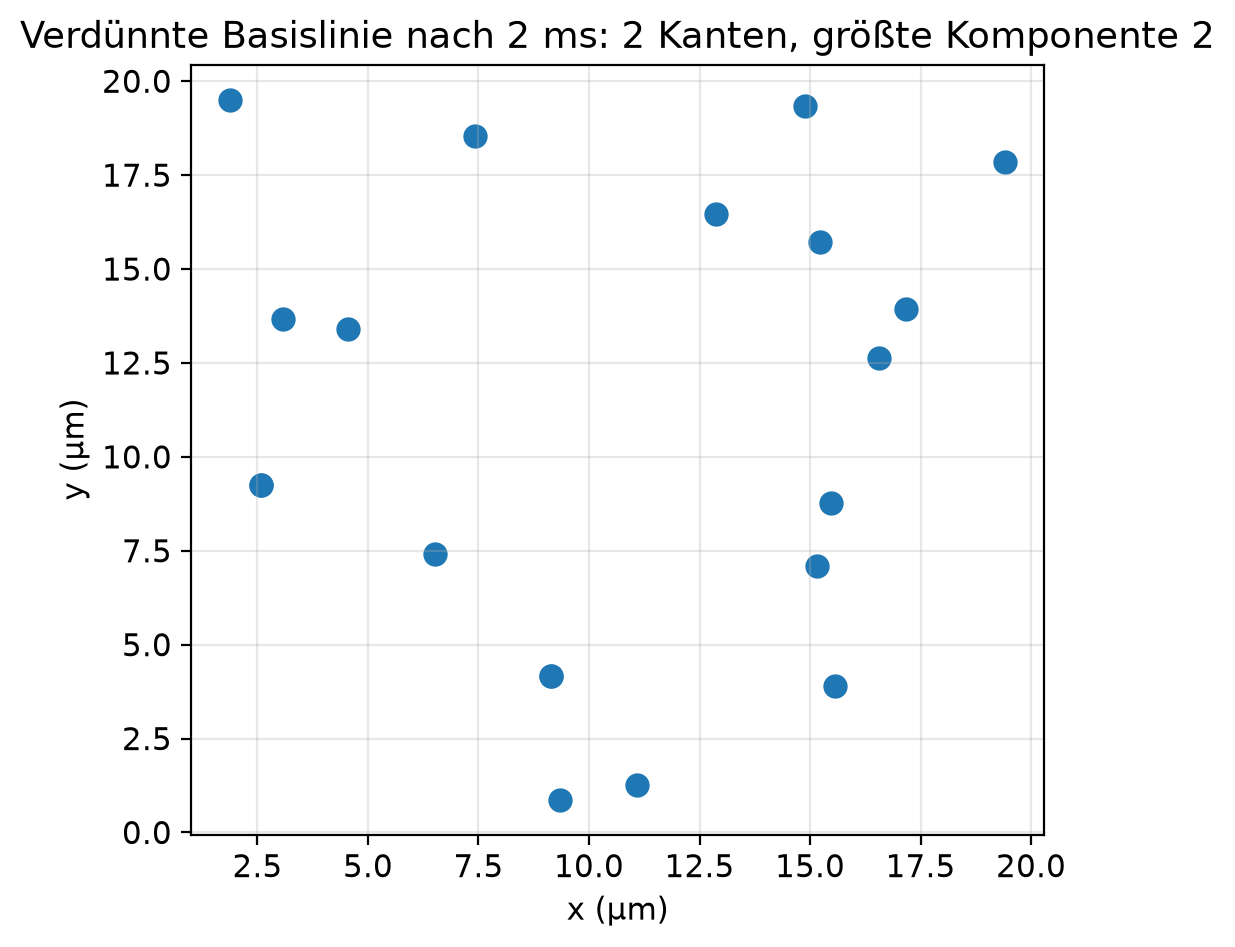

{'largest_cluster': 2, 'n_components': 18, 'mean_degree': 0.2, 'n_edges': 2}

In [2]:
model = ProtocellForces(A_H=5e-21)
frames = run_cluster(model, "cl_retarded", None, n=20, steps=20_000,
                      record_every=100, seed=SEED)
t, x, pair_rows = frames[-1]
m = cluster_metrics(pair_rows, 20)

fig, ax = plt.subplots(figsize=(5.5, 5.0))
ax.scatter(x[:, 0] / 1e-6, x[:, 1] / 1e-6, s=60)
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax.set_title(f"Verdünnte Basislinie nach {t*1e3:.0f} ms: "
             f"{m['n_edges']} Kanten, größte Komponente {m['largest_cluster']}")
save_fig(fig, "07_verduennte_basislinie")
plt.show()
m


**Ergebnis:** Kein einziger Kontakt in Reichweite – der Kontaktgraph ist leer.
Das ist kein Artefakt, sondern die physikalische Aussage von §10 für den
fern-getrennten Bereich: Einzelpaar-Kräfte von 2–100 nm sind zu schwach, um
Cluster aus einer verdünnten Suspension zu formen. Für Clusterbildung braucht es
Mehrkörper-/Geometrie-Effekte oder vorgeformte Aggregate (Szenario 2).

## Szenario 2: Persistenz vorgeclusterter Starts (Abstands-Sweep)

Gitterstart mit Oberflächenabstand L₀ ∈ {5, 20, 50} nm; Modi dlvo vs.
cl_retarded; PMBC vs. Fettsäure; N = 20, 5×10⁴ Schritte. Beobachtet: größte
zusammenhängende Komponente über der Zeit.

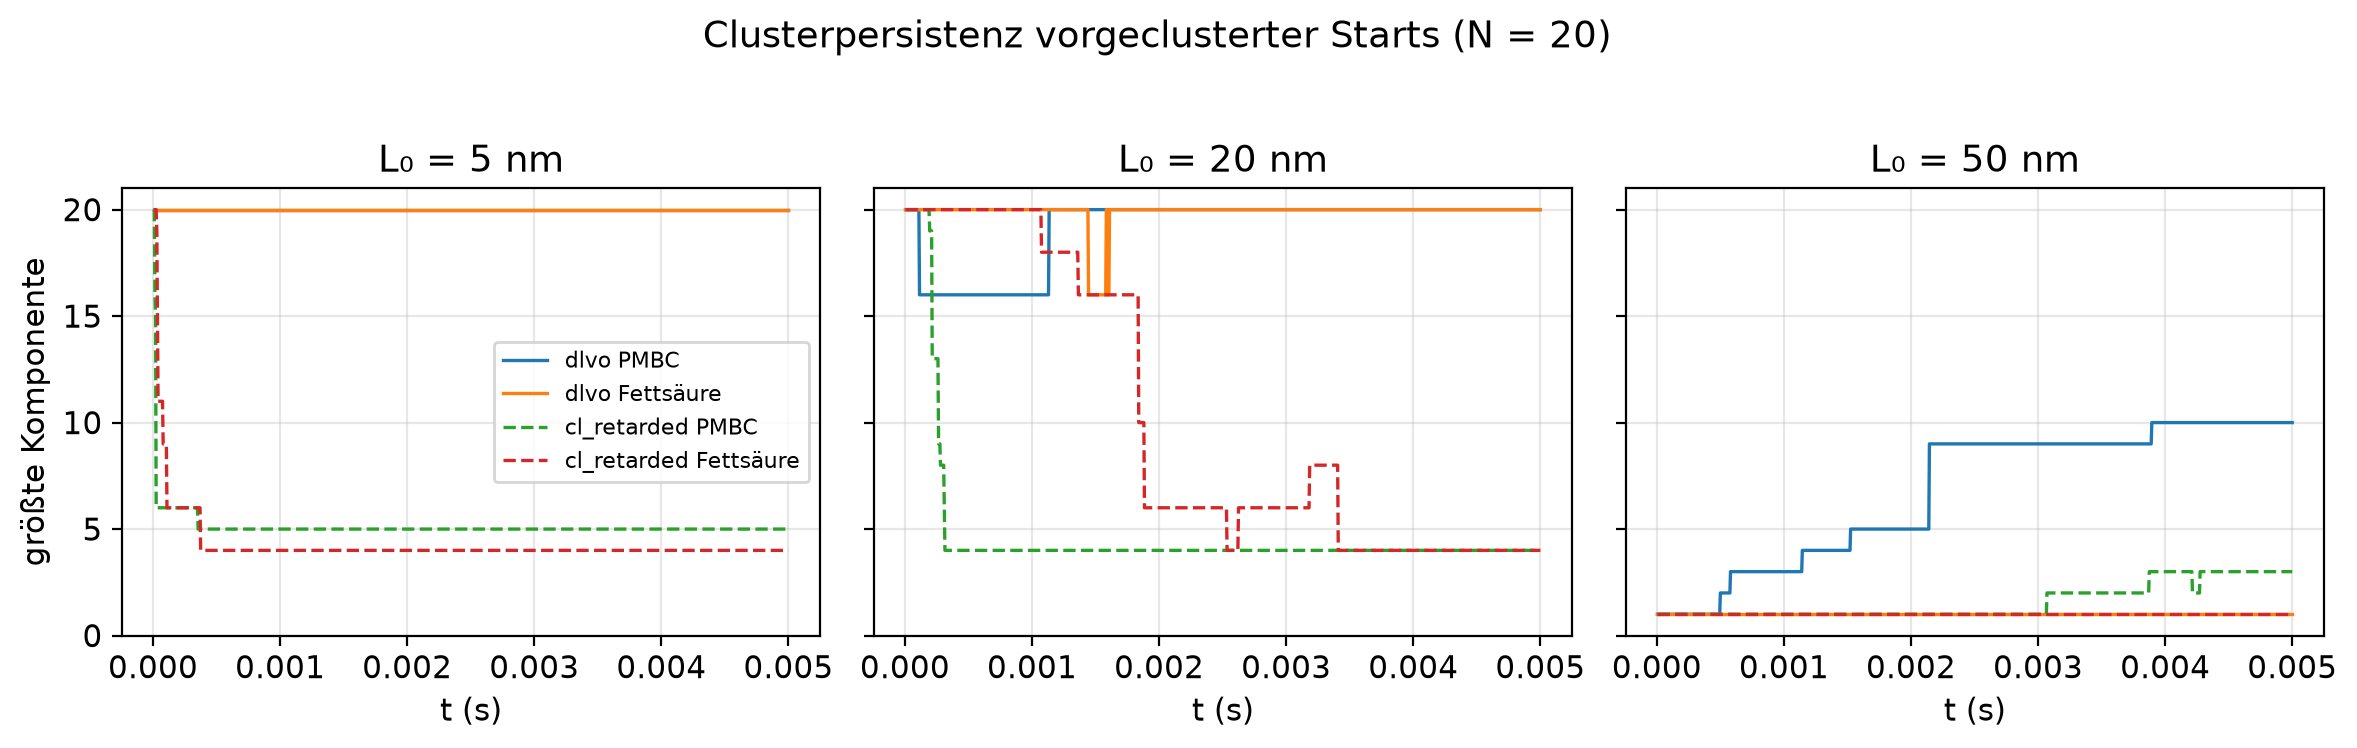

In [3]:
GAPS = [5e-9, 20e-9, 50e-9]
STEPS_SWEEP = 50_000
results = {}
for gap in GAPS:
    for mode in ("dlvo", "cl_retarded"):
        for material, A_H in MATERIALS.items():
            model = ProtocellForces(A_H=A_H)
            x0 = lattice_positions(20, BOX, R_NM * 1e-9, gap, seed=SEED)
            frames = run_cluster(model, mode, x0, 20, STEPS_SWEEP, seed=SEED)
            results[(gap, mode, material)] = frames

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, gap in zip(axes, GAPS):
    for (g, mode, material), frames in results.items():
        if g != gap:
            continue
        ts = [t for t, _, _ in frames]
        largest = [cluster_metrics(pr, 20)["largest_cluster"] for _, _, pr in frames]
        style = "-" if mode == "dlvo" else "--"
        ax.plot(ts, largest, style, lw=1.2, label=f"{mode} {material}")
    ax.set_title(f"L₀ = {gap/1e-9:.0f} nm")
    ax.set_xlabel("t (s)")
    ax.set_ylim(0, 21)
axes[0].set_ylabel("größte Komponente")
axes[0].legend(fontsize=8)
fig.suptitle("Clusterpersistenz vorgeclusterter Starts (N = 20)", y=1.03)
fig.tight_layout()
save_fig(fig, "08_clusterpersistenz_gap_sweep")
plt.show()


In [4]:
rows = []
for (gap, mode, material), frames in results.items():
    tail = frames[-10:]  # letzte 10 aufgezeichnete Frames
    largest = np.mean([cluster_metrics(pr, 20)["largest_cluster"] for _, _, pr in tail])
    edges = np.mean([cluster_metrics(pr, 20)["n_edges"] for _, _, pr in tail])
    rows.append({"L₀ (nm)": gap / 1e-9, "Modus": mode, "Material": material,
                 "⟨größte Komponente⟩": largest, "⟨Kanten⟩": edges})
pd.DataFrame(rows)

,L₀ (nm),Modus,Material,⟨größte Komponente⟩,⟨Kanten⟩
0,5.0,dlvo,PMBC,20.0,31.0
1,5.0,dlvo,Fettsäure,20.0,31.0
2,5.0,cl_retarded,PMBC,5.0,28.0
3,5.0,cl_retarded,Fettsäure,4.0,22.0
4,20.0,dlvo,PMBC,20.0,29.0
5,20.0,dlvo,Fettsäure,20.0,28.0
6,20.0,cl_retarded,PMBC,4.0,25.0
7,20.0,cl_retarded,Fettsäure,4.0,25.0
8,50.0,dlvo,PMBC,10.0,20.0
9,50.0,dlvo,Fettsäure,1.0,0.0


## Clustergrößenverteilungen für N = 10–50 (Pflichtplot)

cl_retarded, PMBC, L₀ = 20 nm: Verteilung der Komponentengrößen über die letzten
aufgezeichneten Frames; zusätzlich ein Kontaktgraph-Snapshot für N = 20.

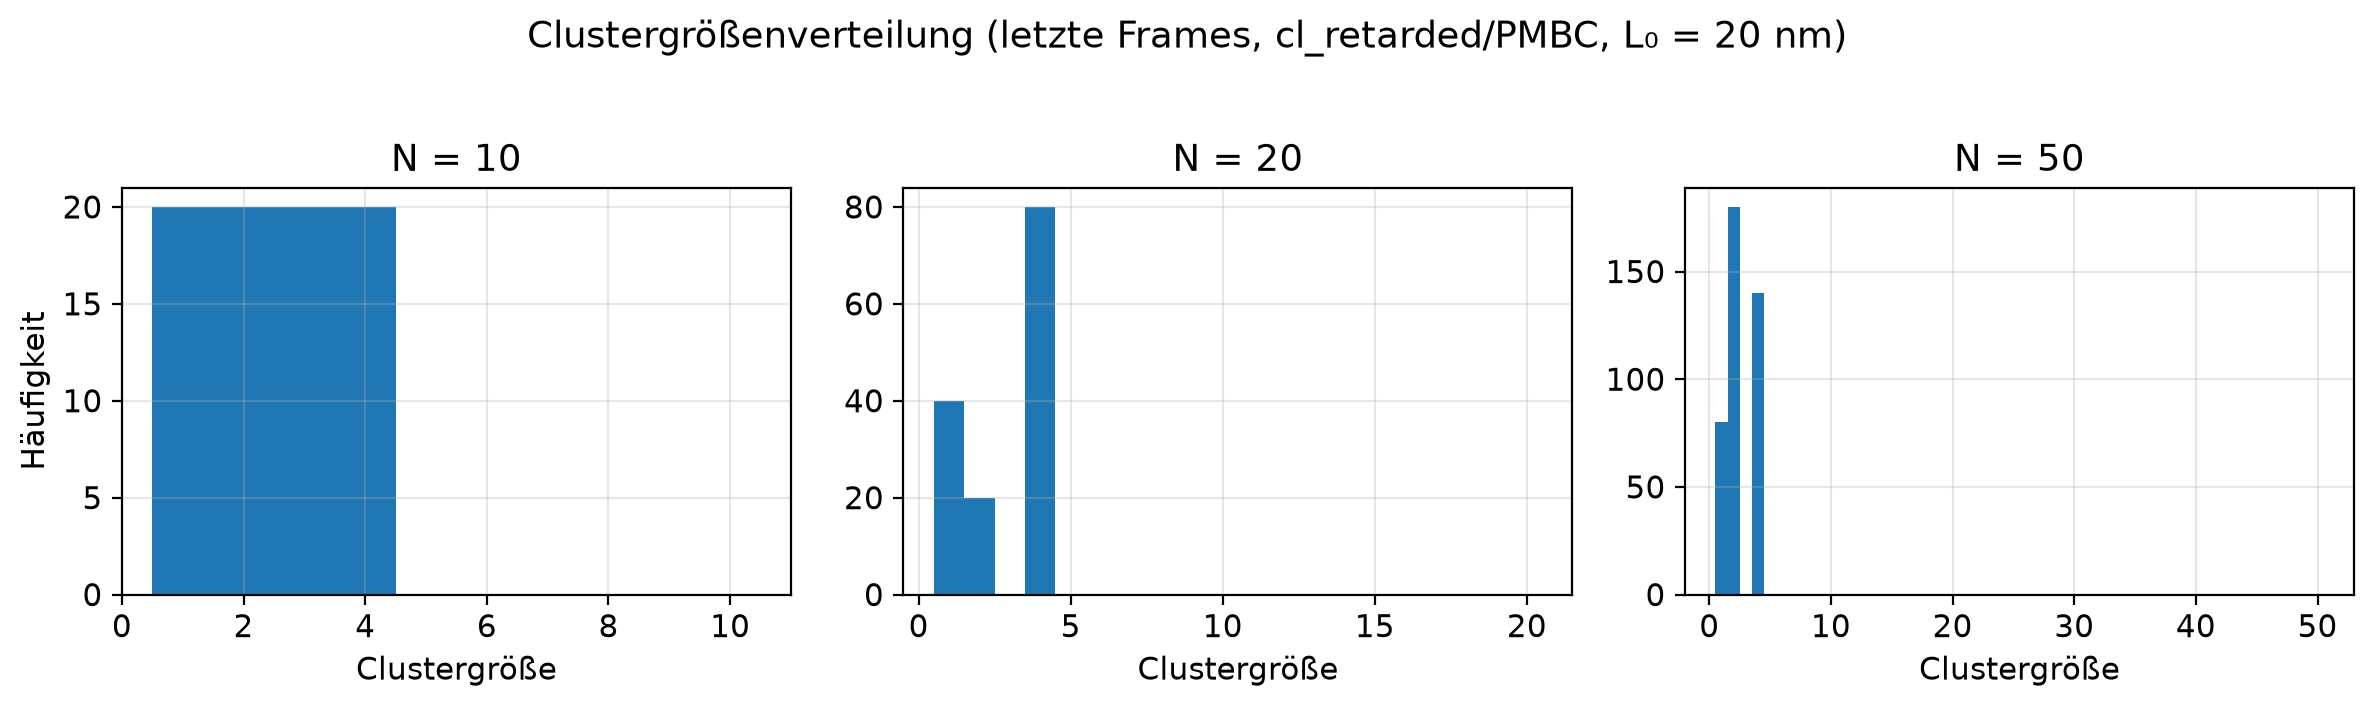

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
model = ProtocellForces(A_H=5e-21)
n_frames = {}
for ax, n in zip(axes, (10, 20, 50)):
    x0 = lattice_positions(n, BOX, R_NM * 1e-9, 20e-9, seed=SEED)
    frames = run_cluster(model, "cl_retarded", x0, n, STEPS_SWEEP, seed=SEED)
    n_frames[n] = frames
    sizes = []
    for _, _, pr in frames[-20:]:
        g = contact_graph(pr, n)
        sizes.extend(len(c) for c in nx.connected_components(g))
    ax.hist(sizes, bins=np.arange(0.5, n + 1.5, 1))
    ax.set_title(f"N = {n}")
    ax.set_xlabel("Clustergröße")
axes[0].set_ylabel("Häufigkeit")
fig.suptitle("Clustergrößenverteilung (letzte Frames, cl_retarded/PMBC, L₀ = 20 nm)", y=1.03)
fig.tight_layout()
save_fig(fig, "09_clustergroessenverteilung")
plt.show()


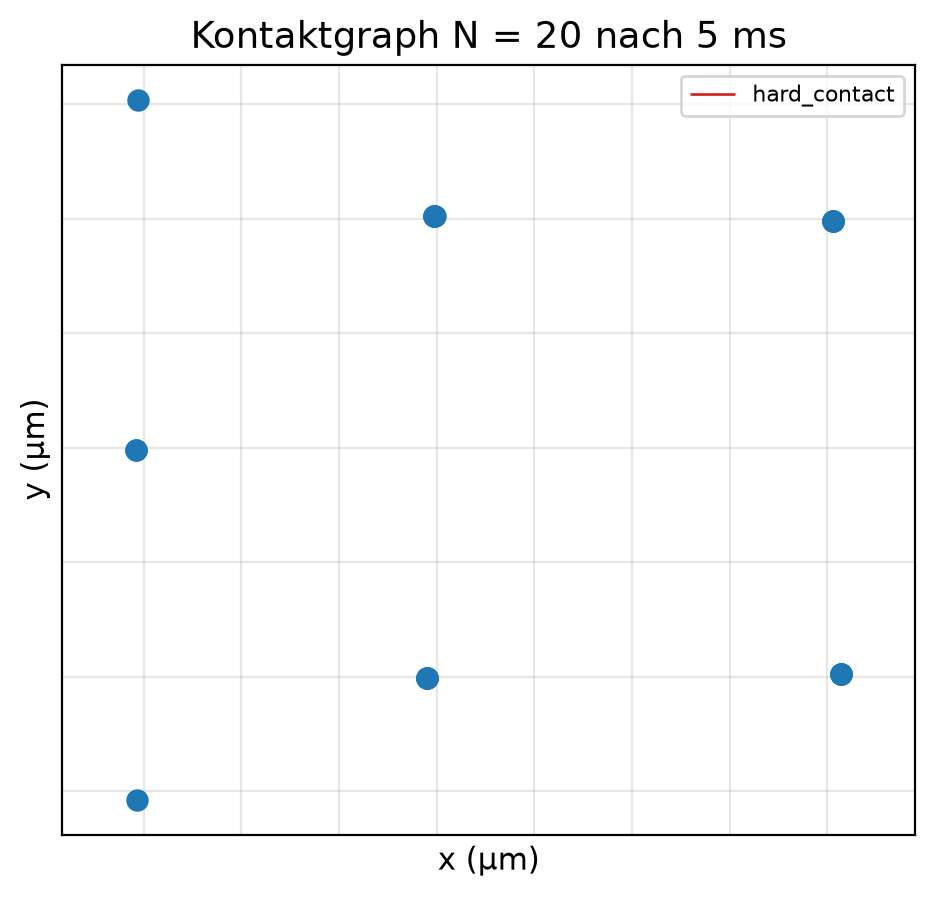

In [6]:
# Kontaktgraph-Snapshot N = 20 (Endzustand des N=20-Laufs)
_, x, pr = n_frames[20][-1]
g = contact_graph(pr, 20)
fig, ax = plt.subplots(figsize=(5.5, 5.0))
pos = {i: (x[i, 0] / 1e-6, x[i, 1] / 1e-6) for i in range(20)}
colors = [g[u][v]["zone"] for u, v in g.edges()]
zone_colors = {"hard_contact": "tab:red", "dlvo_zone": "tab:orange",
               "near_gap": "gold", "meso_gap": "tab:green"}
nx.draw_networkx_nodes(g, pos, node_size=50, ax=ax)
for zone, color in zone_colors.items():
    edges = [(u, v) for u, v in g.edges() if g[u][v]["zone"] == zone]
    if edges:
        nx.draw_networkx_edges(g, pos, edgelist=edges, edge_color=color, ax=ax, label=zone)
ax.legend(fontsize=8)
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax.set_title(f"Kontaktgraph N = 20 nach {n_frames[20][-1][0]*1e3:.0f} ms")
save_fig(fig, "10_kontaktgraph_snapshot")
plt.show()

## Übergabe an Team 2 (§17)

19 Runs, vorgeclusterter Start (L₀ = 20 nm), Salz 100 mM, dt = 1×10⁻⁷ s,
5×10⁴ Schritte, Aufzeichnung alle 50 Schritte (1000 Frames/Run):

- N = 20: {vdw, dlvo, cl_retarded} × {PMBC A_H = 5e-21, Fettsäure
  A_H = 0.5e-21} × Seeds {0, 1, 42} = 18 Runs;
- N = 50: cl_retarded/PMBC, Seed 42 = 1 getrennter explorativer Run.

`pairs.csv` enthält nur Paare mit L < 100 nm (Zone ≠ separated) –
entfernte Paare kann Team 2 aus x, y selbst rekonstruieren.


In [7]:
EXPORT_STEPS = 50_000
RECORD_EVERY = 50
EXPORT_SEEDS = (0, 1, 42)
# 3 Modelle x 2 Materialien x 3 Seeds, jeweils N = 20.
F20_CONFIGS = [
    (mode, A_H, 20, seed)
    for mode in ("vdw", "dlvo", "cl_retarded")
    for A_H in (0.5e-21, 5e-21)
    for seed in EXPORT_SEEDS
]
# Eigener explorativer Lauf; wird im Team-2-Vergleich nicht mit N=20 gepoolt.
EXPORT_CONFIGS = F20_CONFIGS + [("cl_retarded", 5e-21, 50, 42)]
# Übergabedateien löschen, damit ein Rerun idempotent regeneriert
for name in ("positions.csv", "pairs.csv", "cluster_metrics.csv", "parameters.csv"):
    p = PROJECT / "data/processed" / name
    if p.exists():
        p.unlink()
for mode, A_H, n, seed in EXPORT_CONFIGS:
    model = ProtocellForces(A_H=A_H)
    x0 = lattice_positions(n, BOX, R_NM * 1e-9, 20e-9, seed=seed)
    frames = run_cluster(
        model, mode, x0, n, EXPORT_STEPS, RECORD_EVERY, seed=seed
    )
    run_id = make_run_id(mode, A_H, 100, n, seed)
    paths = export_run(
        out_dir=PROJECT / "data/processed",
        run_id=run_id, seed=seed, model_type=mode, A_H=A_H,
        lambda_D=DEBYE_LENGTHS[100], noise=1e-16, T=298.15, R_nm=R_NM,
        salt_mM=100, L_ret_nm=20.0, p_ret=2, dt=DT, mobility=1e8,
        diffusion=1e-16, frames=frames,
    )
    print(run_id, len(frames), "Frames")


vdw_A5.0e-22_I100_N20_s0 1000 Frames


vdw_A5.0e-22_I100_N20_s1 1000 Frames


vdw_A5.0e-22_I100_N20_s42 1000 Frames


vdw_A5.0e-21_I100_N20_s0 1000 Frames


vdw_A5.0e-21_I100_N20_s1 1000 Frames


vdw_A5.0e-21_I100_N20_s42 1000 Frames


... (9 outputs left out)

cl_retarded_A5.0e-21_I100_N20_s0 1000 Frames


cl_retarded_A5.0e-21_I100_N20_s1 1000 Frames


cl_retarded_A5.0e-21_I100_N20_s42 1000 Frames


cl_retarded_A5.0e-21_I100_N50_s42 1000 Frames


In [8]:
# Verifikation der Übergabedateien (Schema und Inhalt)
for name in ("positions.csv", "pairs.csv", "cluster_metrics.csv", "parameters.csv"):
    df = pd.read_csv(PROJECT / "data/processed" / name)
    print(f"{name}: {df.shape[0]} Zeilen, {df.shape[1]} Spalten")
pairs_df = pd.read_csv(PROJECT / "data/processed" / "pairs.csv")
print()
print(pairs_df.contact_zone.value_counts())
print()
print("run_ids:", sorted(pairs_df.run_id.unique()))

positions.csv: 410000 Zeilen, 11 Spalten


pairs.csv: 545316 Zeilen, 8 Spalten
cluster_metrics.csv: 19000 Zeilen, 7 Spalten
parameters.csv: 19 Zeilen, 10 Spalten



contact_zone
hard_contact    352483
meso_gap        104033
dlvo_zone        50623
far_gap          33990
near_gap          4187
Name: count, dtype: int64

run_ids: ['cl_retarded_A5.0e-21_I100_N20_s0', 'cl_retarded_A5.0e-21_I100_N20_s1', 'cl_retarded_A5.0e-21_I100_N20_s42', 'cl_retarded_A5.0e-21_I100_N50_s42', 'cl_retarded_A5.0e-22_I100_N20_s0', 'cl_retarded_A5.0e-22_I100_N20_s1', 'cl_retarded_A5.0e-22_I100_N20_s42', 'dlvo_A5.0e-21_I100_N20_s0', 'dlvo_A5.0e-21_I100_N20_s1', 'dlvo_A5.0e-21_I100_N20_s42', 'dlvo_A5.0e-22_I100_N20_s0', 'dlvo_A5.0e-22_I100_N20_s1', 'dlvo_A5.0e-22_I100_N20_s42', 'vdw_A5.0e-21_I100_N20_s0', 'vdw_A5.0e-21_I100_N20_s1', 'vdw_A5.0e-21_I100_N20_s42', 'vdw_A5.0e-22_I100_N20_s0', 'vdw_A5.0e-22_I100_N20_s1', 'vdw_A5.0e-22_I100_N20_s42']


## Interpretation (streng nach §10)

- **Verdünnt:** keine Cluster aus Einzelpaar-Kräften – konsistent mit §10 für
  30–100 nm (Einzelpaar-Kräfte schwach; Mehrkörper-/Geometrieeffekte nötig).
- **Vorgeclustert, L₀ = 5 nm:** Kontakte liegen in dlvo_zone/near_gap; PMBC-Kontakte
  persistieren, Fettsäure- und dlvo-Configs zeigen Core-abgestoßene Dynamik.
- **L₀ = 20 nm:** Kontakte in meso_gap halten über die Simulationszeit – hier kann
  Standard-Lifshitz-/CL-Kopplung plausibel zur Stabilisierung beitragen, besonders
  für PMBC-artige Protozellen (genau die §10-Aussage für 2–30 nm).
- **L₀ = 50 nm:** Start außerhalb der Kontaktzonen; die Kräfte schließen die Lücke
  in machbarer Zeit nicht – Einzelpaar-Kräfte sind dort zu schwach. Das *ist* das
  Ergebnis, keine Modellpanne.
- **Keine Überbehauptung:** CL erklärt Clusterbildung von 2–100 nm nicht vollständig;
  die Daten zeigen Persistenz vorgeformter Kontakte, nicht spontane Aggregation.